# T24 · Feature importance: quais variáveis o modelo mais usa?

**Issue:** #24 · **Fase 4 · Avaliação e Interpretação** · **Dataset:** `data/raw/cardio_train.csv` · **Conjunto de variáveis:** A (as 11 originais, o do modelo final)

**Objetivo:** mostrar **quais variáveis mais pesam** nas decisões dos modelos e se isso **bate com o conhecimento clínico**. Três jeitos
complementares de medir (funções em `cardio.models.explain`):

1. **Importância nativa das árvores** (Random Forest e XGBoost): quanto cada variável foi usada pelas árvores para separar doentes de saudáveis.
2. **Odds ratio da Regressão Logística**: por quanto a **chance** de doença é multiplicada a cada incremento de uma variável (ex.: a cada 10 mmHg).
3. **Importância por permutação**: quanto o modelo **piora** quando os valores de uma variável são embaralhados. Vale para qualquer modelo.

> **Qual modelo é avaliado.** O modelo final da T23 (XGBoost, conjunto A) foi treinado com treino **e** validação, então a validação deixou
> de ser dado novo para ele. Para a permutação ser honesta, aqui os três modelos são treinados **só no treino**, com os mesmos
> hiperparâmetros do modelo final, e avaliados na **validação**, que eles nunca viram. O teste **não** é usado.
> Importância mostra **o que o modelo usa**, não o que **causa** a doença.

In [1]:
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.metrics import roc_auc_score

from cardio.config import FIGURES_DIR
from cardio.data.preprocessing import load_splits
from cardio.models.estimators import logistic, random_forest, xgb
from cardio.models.explain import (
    comparar_rankings,
    importancia_nativa,
    importancia_por_permutacao,
    odds_ratios_clinicos,
    plot_importancias,
    plot_odds_ratios,
    plot_ranking,
    shap_importancia,
    shap_values,
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def mostrar(caminho) -> None:
    """Mostra uma figura já salva em results/figures/."""
    display(Image(filename=str(caminho)))


def pct(valor: float, casas: int = 0) -> str:
    """Formata uma proporção (0–1) como porcentagem no padrão brasileiro: 0.497 -> '49,7%'."""
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor: float, casas: int = 2) -> str:
    """Formata um número com vírgula decimal: 0.238 -> '0,24'."""
    return f"{valor:.{casas}f}".replace(".", ",")


def inteiro(valor: int) -> str:
    """Formata um inteiro com ponto de milhar: 68588 -> '68.588'."""
    return f"{valor:,}".replace(",", ".")


def texto(conteudo: str) -> None:
    """Mostra um texto de interpretação formatado em Markdown."""
    display(Markdown(conteudo))

## 1. Modelos e dados

Regressão Logística, Random Forest e XGBoost, com os hiperparâmetros padrão de cada `estimators/*.py` (os do XGBoost são os escolhidos
com `tune()` na T18 e usados no modelo final). Todos treinam só com o **treino**.

In [2]:
X_train, X_val, _, y_train, y_val, _ = load_splits("A", save_ids=False)  # o teste não é usado

MODELOS = {"Regressão Logística": logistic, "Random Forest": random_forest, "XGBoost": xgb}
modelos = {nome: modulo.build_model(X_train).fit(X_train, y_train) for nome, modulo in MODELOS.items()}

print(f"Treino: {inteiro(len(X_train))} pacientes | validação: {inteiro(len(X_val))} pacientes | {X_train.shape[1]} variáveis (conjunto A)")
pd.DataFrame(
    {"AUC na validação": {nome: roc_auc_score(y_val, modelo.predict_proba(X_val)[:, 1]) for nome, modelo in modelos.items()}}
).round(4)

Treino: 47.955 pacientes | validação: 10.277 pacientes | 11 variáveis (conjunto A)


,AUC na validação
Regressão Logística,0.7831
Random Forest,0.7908
XGBoost,0.7919


## 2. Importância nativa das árvores

O **Random Forest** mede quanto cada variável reduziu a "impureza" (mistura de doentes e saudáveis) nas divisões das árvores. O **XGBoost** mede o
**ganho** médio que cada variável trouxe. Os valores são normalizados para somar **100%**.

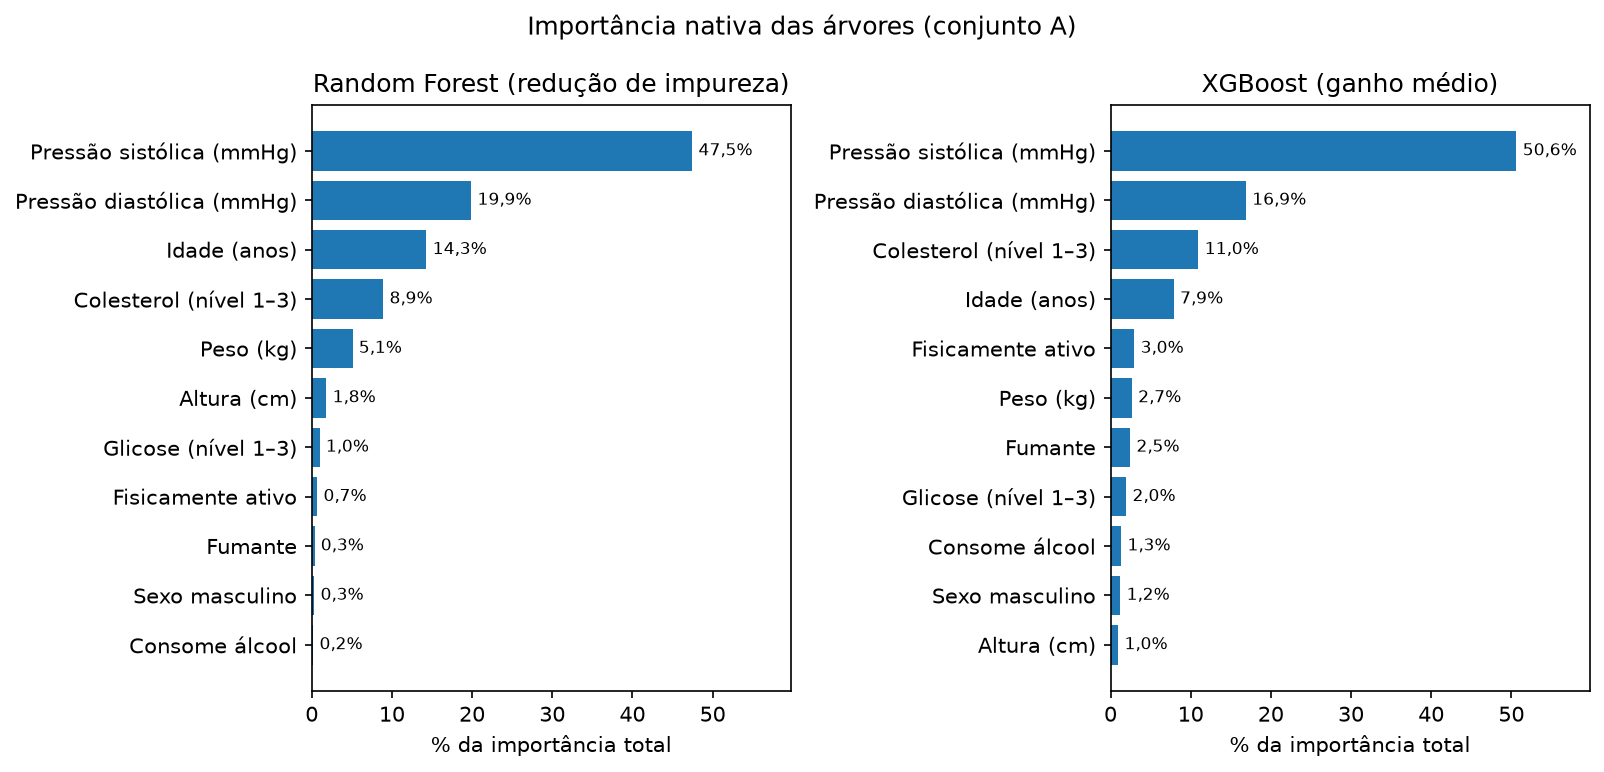

In [3]:
nat_rf = importancia_nativa(modelos["Random Forest"])
nat_xgb = importancia_nativa(modelos["XGBoost"])

mostrar(plot_importancias(
    {"Random Forest (redução de impureza)": nat_rf, "XGBoost (ganho médio)": nat_xgb},
    "importancia", FIGURES_DIR / "t24_importancia_nativa.png",
    "Importância nativa das árvores (conjunto A)", "% da importância total", percentual=True,
))

In [4]:
rf, xg = nat_rf.set_index("variavel")["importancia"], nat_xgb.set_index("variavel")["importancia"]
topo_rf, topo_xg = nat_rf["variavel"].iloc[0], nat_xgb["variavel"].iloc[0]

if topo_rf == topo_xg:
    abertura = f"nos dois modelos a variável mais importante é a **{topo_rf}** ({pct(rf[topo_rf])} no Random Forest e {pct(xg[topo_rf])} no XGBoost)."
else:
    abertura = f"o Random Forest e o XGBoost divergem na primeira posição: **{topo_rf}** ({pct(rf[topo_rf])}) e **{topo_xg}** ({pct(xg[topo_xg])})."

texto(f"""**Interpretação:** {abertura}
As três primeiras variáveis somam {pct(nat_rf["importancia"].head(3).sum())} da importância no Random Forest e
{pct(nat_xgb["importancia"].head(3).sum())} no XGBoost; as demais dividem o resto.

**Cuidado:** esse tipo de importância tem um viés conhecido, pois **favorece variáveis contínuas e variáveis correlacionadas com
outras**. A seção 5 compara estes números com a permutação, que não tem esse viés.""")

**Interpretação:** nos dois modelos a variável mais importante é a **Pressão sistólica (mmHg)** (47% no Random Forest e 51% no XGBoost).
As três primeiras variáveis somam 82% da importância no Random Forest e
78% no XGBoost; as demais dividem o resto.

**Cuidado:** esse tipo de importância tem um viés conhecido, pois **favorece variáveis contínuas e variáveis correlacionadas com
outras**. A seção 5 compara estes números com a permutação, que não tem esse viés.

## 3. Regressão Logística: odds ratio

O **odds ratio** diz por quanto a **chance** de doença é multiplicada: **1,50** significa 50% a mais de chance; **0,80**, 20% a menos. Vale
**mantendo as outras variáveis iguais**. Para as variáveis contínuas é lido por incremento clínico (ex.: a cada 10 mmHg); para colesterol e
glicose, por nível; para as binárias, sim × não.

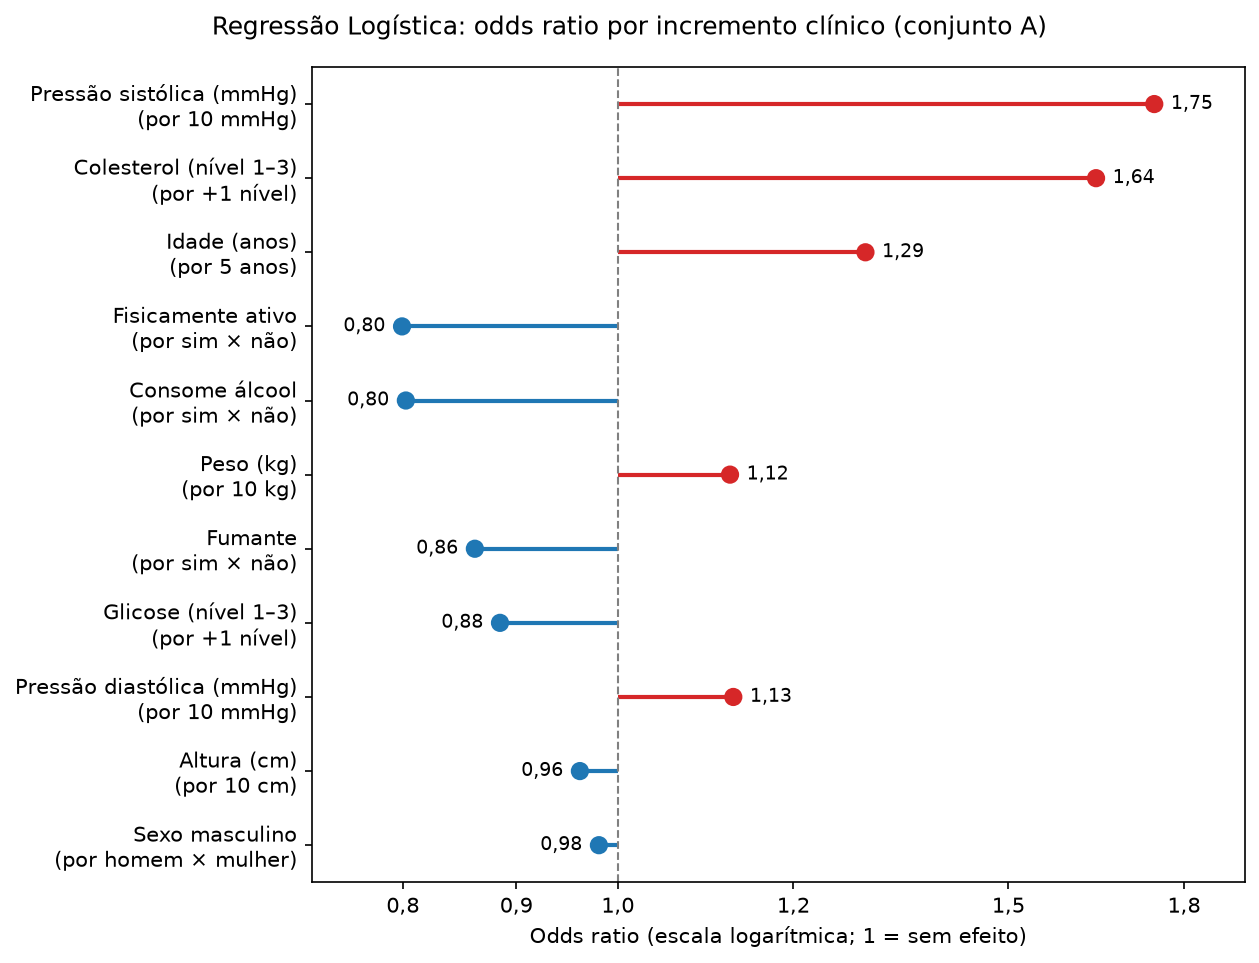

,variavel,incremento,odds_ratio,odds_ratio_por_desvio
0,Pressão sistólica (mmHg),10 mmHg,1.75,2.54
1,Colesterol (nível 1–3),+1 nível,1.64,1.64
2,Idade (anos),5 anos,1.29,1.42
3,Fisicamente ativo,sim × não,0.80,0.80
4,Consome álcool,sim × não,0.80,0.80
5,Peso (kg),10 kg,1.12,1.18
6,Fumante,sim × não,0.86,0.86
7,Glicose (nível 1–3),+1 nível,0.88,0.88
8,Pressão diastólica (mmHg),10 mmHg,1.13,1.12
9,Altura (cm),10 cm,0.96,0.97


In [5]:
tab_or = odds_ratios_clinicos(modelos["Regressão Logística"])

mostrar(plot_odds_ratios(
    tab_or, FIGURES_DIR / "t24_odds_ratio_regressao.png",
    "Regressão Logística: odds ratio por incremento clínico (conjunto A)",
))
tab_or.assign(odds_ratio=tab_or["odds_ratio"].round(2), odds_ratio_por_desvio=tab_or["odds_ratio_por_desvio"].round(2))

In [6]:
orc = tab_or.set_index("variavel")["odds_ratio"]
sistolica, diastolica, idade, colesterol, peso = (
    orc["Pressão sistólica (mmHg)"], orc["Pressão diastólica (mmHg)"], orc["Idade (anos)"],
    orc["Colesterol (nível 1–3)"], orc["Peso (kg)"],
)
abaixo_de_1 = [v for v in ("Fumante", "Consome álcool", "Glicose (nível 1–3)") if orc[v] < 1]
corr_gluc_col = X_train["cholesterol"].corr(X_train["gluc"], method="spearman")

texto(f"""**Interpretação** (mantendo as outras variáveis iguais):

- **Pressão sistólica:** a cada **10 mmHg** a mais, a chance de doença é multiplicada por **{num(sistolica)}** ({pct(sistolica - 1)} maior).
- **Idade:** a cada **5 anos** a mais, a chance é multiplicada por **{num(idade)}** ({pct(idade - 1)} maior).
- **Colesterol:** a cada **nível** a mais (normal → acima → muito acima), por **{num(colesterol)}** ({pct(colesterol - 1)} maior).
- **Peso** (a cada 10 kg: {num(peso)}) e **pressão diastólica** (a cada 10 mmHg: {num(diastolica)}) têm efeito menor.

{f"**{', '.join(abaixo_de_1)}** aparecem com odds ratio **abaixo de 1** ({', '.join(num(orc[v]) for v in abaixo_de_1)}), o que sugeriria um efeito protetor. Não deve ser lido assim: fumo e álcool são autodeclarados e já tinham sinal contrário ao esperado na EDA (T06); a glicose anda junto com o colesterol (correlação de Spearman de {num(corr_gluc_col)} entre elas) e, com o colesterol no modelo, ela quase não acrescenta nada." if abaixo_de_1 else ""}

O odds ratio **não compara variáveis entre si** (10 mmHg não é o mesmo que "1 nível de colesterol"). Para comparar, a coluna
`odds_ratio_por_desvio` usa a mesma régua (1 desvio-padrão de cada variável).""")

**Interpretação** (mantendo as outras variáveis iguais):

- **Pressão sistólica:** a cada **10 mmHg** a mais, a chance de doença é multiplicada por **1,75** (75% maior).
- **Idade:** a cada **5 anos** a mais, a chance é multiplicada por **1,29** (29% maior).
- **Colesterol:** a cada **nível** a mais (normal → acima → muito acima), por **1,64** (64% maior).
- **Peso** (a cada 10 kg: 1,12) e **pressão diastólica** (a cada 10 mmHg: 1,13) têm efeito menor.

**Fumante, Consome álcool, Glicose (nível 1–3)** aparecem com odds ratio **abaixo de 1** (0,86, 0,80, 0,88), o que sugeriria um efeito protetor. Não deve ser lido assim: fumo e álcool são autodeclarados e já tinham sinal contrário ao esperado na EDA (T06); a glicose anda junto com o colesterol (correlação de Spearman de 0,40 entre elas) e, com o colesterol no modelo, ela quase não acrescenta nada.

O odds ratio **não compara variáveis entre si** (10 mmHg não é o mesmo que "1 nível de colesterol"). Para comparar, a coluna
`odds_ratio_por_desvio` usa a mesma régua (1 desvio-padrão de cada variável).

## 4. Importância por permutação (validação)

Para cada variável, os valores dela são **embaralhados** entre os pacientes da validação (10 vezes) e se mede o quanto a **AUC** do modelo cai. Se o
modelo piora muito, ele dependia daquela variável; se não muda, ela não ajudava. A barra cinza mostra o desvio entre as 10 repetições. É a única
medida aqui que vale **igual para os três modelos**.

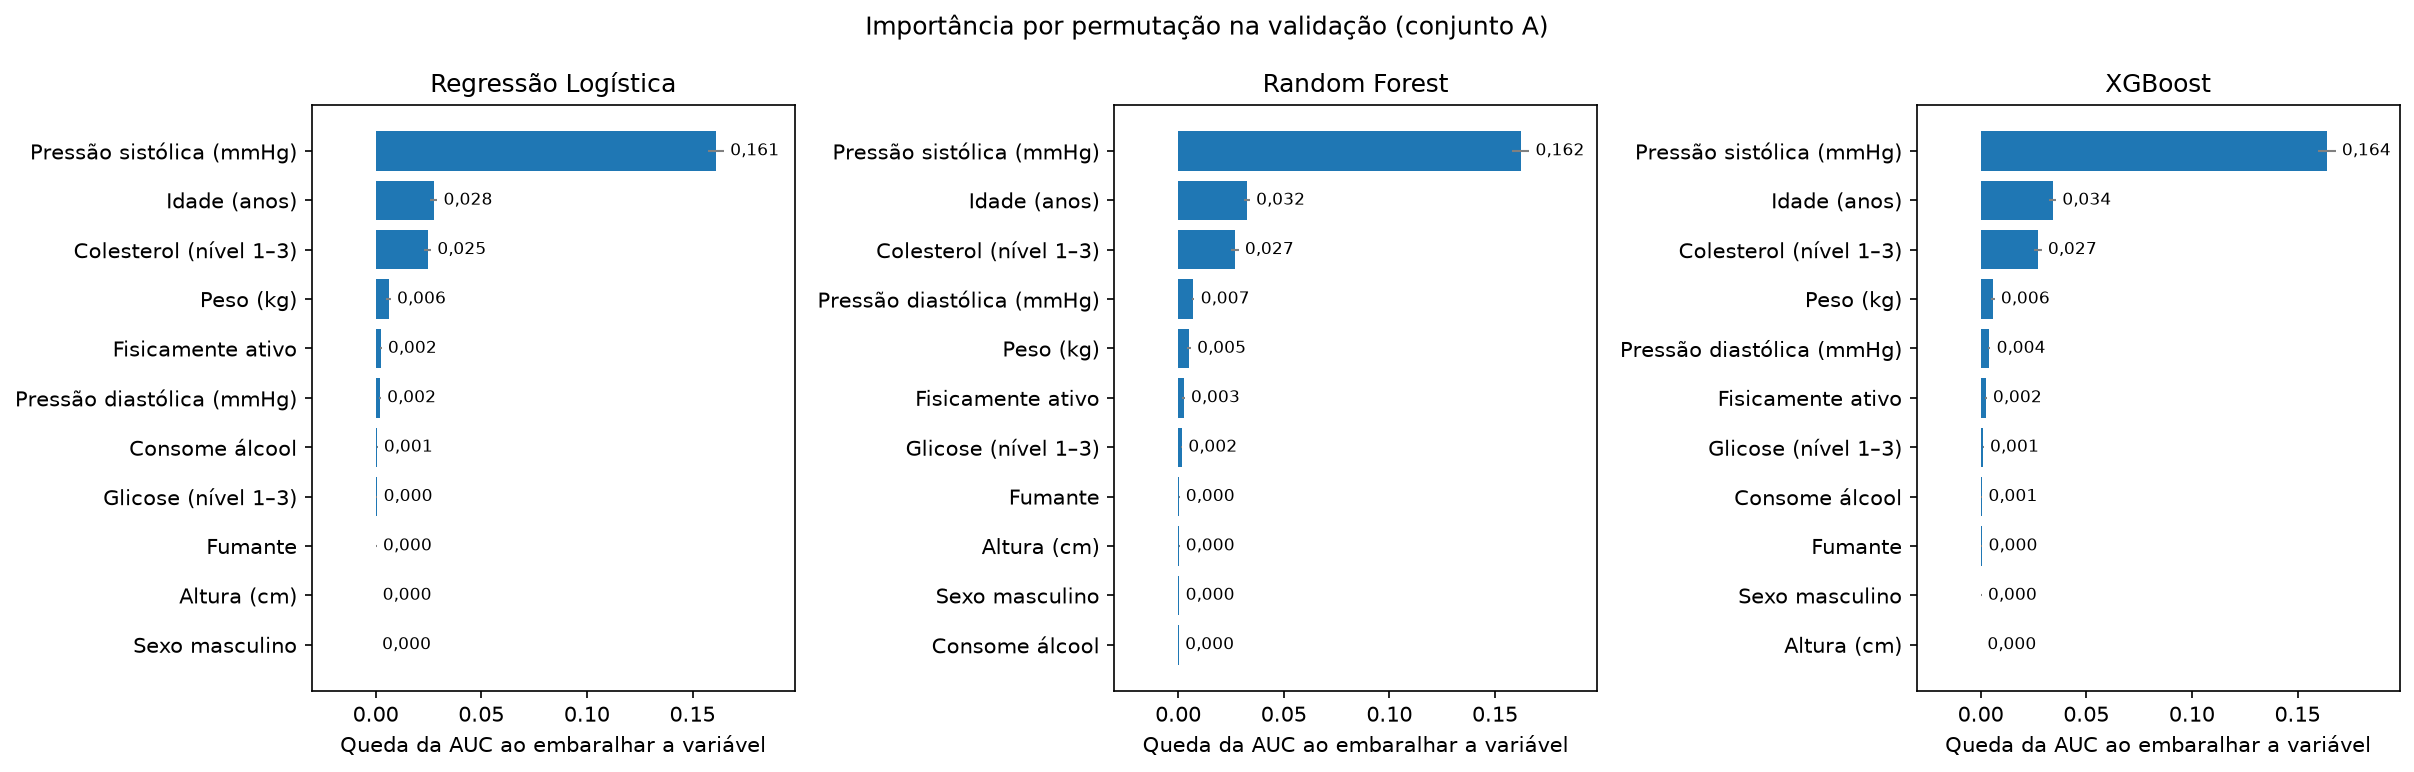

In [7]:
perm = {nome: importancia_por_permutacao(modelo, X_val, y_val, n_repeats=10) for nome, modelo in modelos.items()}

mostrar(plot_importancias(
    perm, "queda_media", FIGURES_DIR / "t24_permutacao.png",
    "Importância por permutação na validação (conjunto A)", "Queda da AUC ao embaralhar a variável", erro="desvio",
))

In [8]:
p = {nome: tabela.set_index("variavel") for nome, tabela in perm.items()}
top3 = {nome: list(tabela["variavel"].head(3)) for nome, tabela in perm.items()}
mesmas_tres = all(t == top3["XGBoost"] for t in top3.values())
primeira = perm["XGBoost"]["variavel"].iloc[0]
segunda, terceira = top3["XGBoost"][1], top3["XGBoost"][2]
no_ruido = [v for v, linha in p["XGBoost"].iterrows() if linha["queda_media"] <= 2 * linha["desvio"]]

texto(f"""**Interpretação:** {"os três modelos concordam nas **três variáveis mais importantes e na ordem delas**" if mesmas_tres else "os modelos divergem nas três primeiras variáveis"}:
**{primeira}**, **{segunda}** e **{terceira}**.

- Embaralhar a **{primeira}** derruba a AUC em **{num(p["Regressão Logística"].loc[primeira, "queda_media"], 3)}** na Regressão Logística,
  **{num(p["Random Forest"].loc[primeira, "queda_media"], 3)}** no Random Forest e **{num(p["XGBoost"].loc[primeira, "queda_media"], 3)}** no XGBoost,
  um efeito **{num(p["XGBoost"].loc[primeira, "queda_media"] / p["XGBoost"].loc[segunda, "queda_media"], 1)} vezes maior** que o da segunda variável ({segunda}) no XGBoost.
- Para dar uma ideia: a AUC do XGBoost na validação é {num(roc_auc_score(y_val, modelos["XGBoost"].predict_proba(X_val)[:, 1]), 3)}; ao embaralhar a pressão sistólica
  ela cai para cerca de {num(roc_auc_score(y_val, modelos["XGBoost"].predict_proba(X_val)[:, 1]) - p["XGBoost"].loc[primeira, "queda_media"], 2)} (0,50 equivale a chutar).
- {f"Variáveis cuja queda é indistinguível de zero (queda menor que 2 desvios) no XGBoost: **{', '.join(no_ruido)}**. O modelo praticamente não as usa." if no_ruido else "Todas as variáveis têm queda acima do ruído."}""")

**Interpretação:** os três modelos concordam nas **três variáveis mais importantes e na ordem delas**:
**Pressão sistólica (mmHg)**, **Idade (anos)** e **Colesterol (nível 1–3)**.

- Embaralhar a **Pressão sistólica (mmHg)** derruba a AUC em **0,161** na Regressão Logística,
  **0,162** no Random Forest e **0,164** no XGBoost,
  um efeito **4,8 vezes maior** que o da segunda variável (Idade (anos)) no XGBoost.
- Para dar uma ideia: a AUC do XGBoost na validação é 0,792; ao embaralhar a pressão sistólica
  ela cai para cerca de 0,63 (0,50 equivale a chutar).
- Variáveis cuja queda é indistinguível de zero (queda menor que 2 desvios) no XGBoost: **Fumante, Altura (cm)**. O modelo praticamente não as usa.

## 5. Comparando os métodos

A tabela mostra a **posição** de cada variável (1 = mais importante) em cada método. Além dos três acima, entram o **SHAP** do XGBoost (T25, contribuição
absoluta média em 1.500 pacientes da validação) e o tamanho do efeito da Regressão Logística por desvio-padrão.

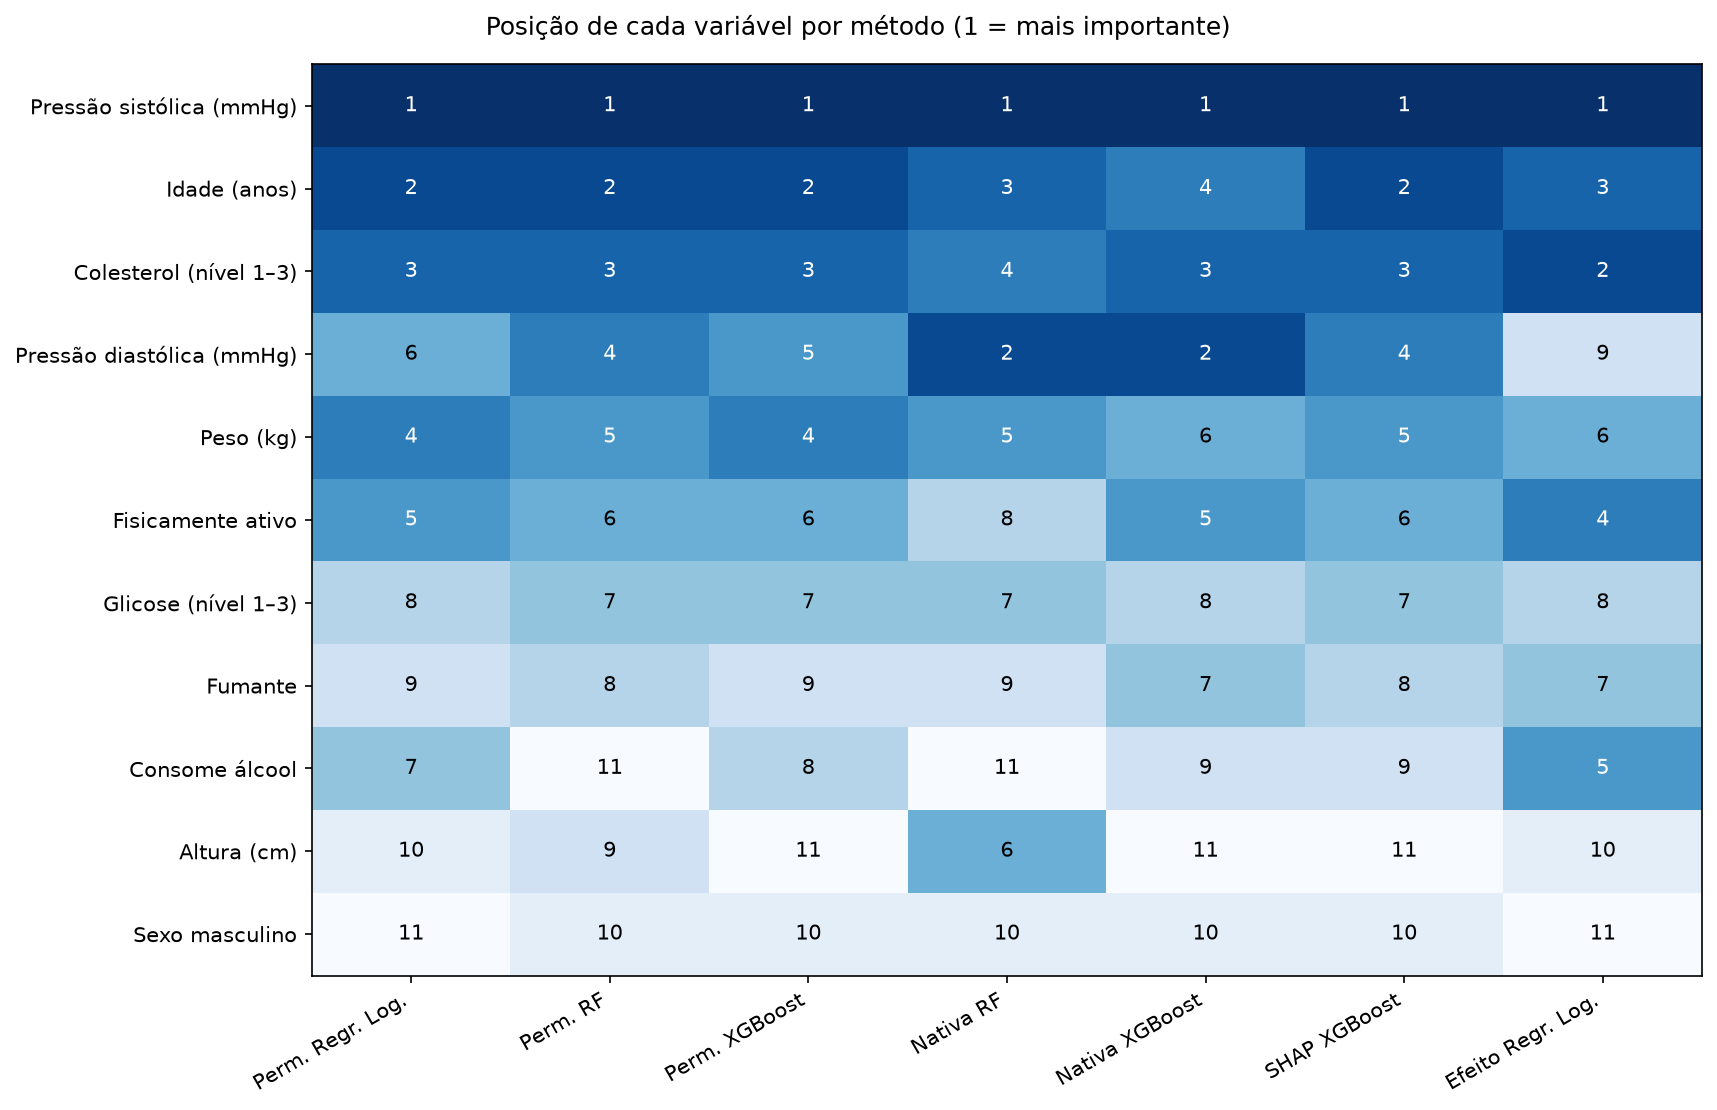

,Perm. Regr. Log.,Perm. RF,Perm. XGBoost,Nativa RF,Nativa XGBoost,SHAP XGBoost,Efeito Regr. Log.
Pressão sistólica (mmHg),1,1,1,1,1,1,1
Idade (anos),2,2,2,3,4,2,3
Colesterol (nível 1–3),3,3,3,4,3,3,2
Pressão diastólica (mmHg),6,4,5,2,2,4,9
Peso (kg),4,5,4,5,6,5,6
Fisicamente ativo,5,6,6,8,5,6,4
Glicose (nível 1–3),8,7,7,7,8,7,8
Fumante,9,8,9,9,7,8,7
Consome álcool,7,11,8,11,9,9,5
Altura (cm),10,9,11,6,11,11,10


In [9]:
explicacao, _ = shap_values(modelos["XGBoost"], X_val, sample_size=1500)
metodos = {
    "Perm. Regr. Log.": p["Regressão Logística"]["queda_media"],
    "Perm. RF": p["Random Forest"]["queda_media"],
    "Perm. XGBoost": p["XGBoost"]["queda_media"],
    "Nativa RF": rf,
    "Nativa XGBoost": xg,
    "SHAP XGBoost": shap_importancia(explicacao),
    "Efeito Regr. Log.": np.abs(np.log(tab_or.set_index("variavel")["odds_ratio_por_desvio"])),
}
ranking = comparar_rankings(metodos)

mostrar(plot_ranking(ranking, FIGURES_DIR / "t24_comparacao_rankings.png",
                     "Posição de cada variável por método (1 = mais importante)"))
ranking

In [10]:
perm_cols = ["Perm. Regr. Log.", "Perm. RF", "Perm. XGBoost"]
spearman = ranking[perm_cols].corr(method="spearman")
menor_spearman = spearman.to_numpy()[np.triu_indices(3, k=1)].min()
ordem_igual = list(ranking.index[:3])
shap_top3 = list(ranking["SHAP XGBoost"].sort_values(kind="stable").index[:3])


def infladas(sigla: str, nativa: str) -> list[str]:
    """Variáveis que a importância nativa coloca 2 ou mais posições acima da permutação."""
    dif = ranking[f"Perm. {sigla}"] - ranking[nativa]
    return [f"**{v}** ({ranking.loc[v, nativa]}ª na nativa contra {ranking.loc[v, f'Perm. {sigla}']}ª na permutação)" for v in dif[dif >= 2].index]


inf_rf, inf_xg = infladas("RF", "Nativa RF"), infladas("XGBoost", "Nativa XGBoost")
corr_pressoes = X_train["ap_hi"].corr(X_train["ap_lo"])

texto(f"""**Interpretação:**

- **Concordância:** as três permutações têm correlação de postos (Spearman) de pelo menos **{num(menor_spearman)}** entre si, e o SHAP do XGBoost
  (T25) {"coloca as mesmas três variáveis no topo" if shap_top3 == list(perm["XGBoost"]["variavel"].head(3)) else "tem um topo diferente"}.
  Os métodos diferem sobretudo no **fim** da lista, onde as importâncias são todas muito pequenas.
- **A importância nativa infla algumas variáveis.** No Random Forest: {"; ".join(inf_rf) if inf_rf else "nenhuma"}.
  No XGBoost: {"; ".join(inf_xg) if inf_xg else "nenhuma"}.
  É o viés esperado da importância nativa: ela conta o quanto uma variável foi usada nas divisões das árvores, mesmo quando esse ganho vem de ruído ou de
  informação que outra variável já traz (a pressão diastólica anda junto com a sistólica, correlação de {num(corr_pressoes)}). Ao embaralhar essas
  variáveis, o modelo quase não piora.
- **A permutação também tem um limite:** quando duas variáveis carregam quase a mesma informação (sistólica e diastólica; peso e altura), embaralhar uma
  é compensado pela outra e a importância **se divide** entre elas. Por isso nenhum método sozinho é definitivo; vale olhar os quatro juntos.""")

**Interpretação:**

- **Concordância:** as três permutações têm correlação de postos (Spearman) de pelo menos **0,88** entre si, e o SHAP do XGBoost
  (T25) coloca as mesmas três variáveis no topo.
  Os métodos diferem sobretudo no **fim** da lista, onde as importâncias são todas muito pequenas.
- **A importância nativa infla algumas variáveis.** No Random Forest: **Pressão diastólica (mmHg)** (2ª na nativa contra 4ª na permutação); **Altura (cm)** (6ª na nativa contra 9ª na permutação).
  No XGBoost: **Pressão diastólica (mmHg)** (2ª na nativa contra 5ª na permutação); **Fumante** (7ª na nativa contra 9ª na permutação).
  É o viés esperado da importância nativa: ela conta o quanto uma variável foi usada nas divisões das árvores, mesmo quando esse ganho vem de ruído ou de
  informação que outra variável já traz (a pressão diastólica anda junto com a sistólica, correlação de 0,74). Ao embaralhar essas
  variáveis, o modelo quase não piora.
- **A permutação também tem um limite:** quando duas variáveis carregam quase a mesma informação (sistólica e diastólica; peso e altura), embaralhar uma
  é compensado pela outra e a importância **se divide** entre elas. Por isso nenhum método sozinho é definitivo; vale olhar os quatro juntos.

## 6. O modelo concorda com o conhecimento clínico?

In [11]:
queda_xg = p["XGBoost"]["queda_media"]
ordem = list(ranking.index)  # da mais para a menos importante, pela posição média nos métodos
auc_xg = roc_auc_score(y_val, modelos["XGBoost"].predict_proba(X_val)[:, 1])

# métodos em que as três primeiras posições são as mesmas, na mesma ordem
exatos = [c for c in ranking.columns if list(ranking[c].sort_values(kind="stable").index[:3]) == ordem[:3]]
sistolica_sempre_primeira = bool((ranking.loc[ordem[0]] == 1).all())


def posicao_perm(variavel: str) -> str:
    """Posição da variável nas três permutações: '5ª' ou '4ª a 5ª'."""
    posicoes = ranking.loc[variavel, perm_cols]
    return f"{posicoes.min()}ª" if posicoes.min() == posicoes.max() else f"{posicoes.min()}ª a {posicoes.max()}ª"


habitos = ["Fumante", "Consome álcool", "Fisicamente ativo"]
queda_habitos = max(p[modelo].loc[v, "queda_media"] for modelo in p for v in habitos)

texto(f"""### Resposta curta

**Sim, em grande parte.** Pressão arterial, idade e colesterol são fatores de risco cardiovascular conhecidos, e são as **três primeiras variáveis** do
modelo ({", ".join(ordem[:3])}), na mesma ordem em **{len(exatos)} dos {len(ranking.columns)} métodos** ({", ".join(exatos)}).
{"Nos demais, a pressão sistólica continua em 1º lugar, mas outra variável entra entre as três primeiras (a diastólica, na importância nativa)." if sistolica_sempre_primeira and len(exatos) < len(ranking.columns) else ""}
A pressão sistólica domina: a queda de AUC ao embaralhá-la é **{num(queda_xg[ordem[0]] / queda_xg[ordem[1]], 1)} vezes** a da segunda variável, e no odds ratio
cada 10 mmHg multiplica a chance de doença por **{num(sistolica)}**.

### O que bate com o esperado

- **Pressão sistólica, idade e colesterol** no topo, e com efeito que **cresce** com o valor (odds ratio acima de 1). Isso também aparece na correlação
  com a doença (EDA, T07) e nas contribuições do SHAP (T25).
- **Peso** fica na {posicao_perm("Peso (kg)")} posição pela permutação, coerente com o excesso de peso como fator de risco; **altura** e **sexo** quase não pesam
  ({posicao_perm("Altura (cm)")} e {posicao_perm("Sexo masculino")} posições).

### O que merece cautela

- **Glicose** ({posicao_perm("Glicose (nível 1–3)")} posição pela permutação): é um fator de risco clássico (diabetes), mas pesa pouco aqui. Ela tem só 3 níveis e anda junto com o
  colesterol (correlação de Spearman de {num(corr_gluc_col)}); uma explicação plausível, **não testada aqui**, é que boa parte da informação dela já entra pelo colesterol.
- **Fumo, álcool e atividade física** pesam pouco (a queda de AUC é menor que {num(queda_habitos + 0.0005, 3)} em qualquer modelo). São **autodeclarados**, e fumo e álcool
  tiveram sinal contrário ao esperado na EDA (T06). O baixo peso pode refletir a **qualidade do dado**, e não que esses hábitos não importem para o coração.
- **Pressão diastólica:** a importância nativa a coloca em 2º lugar, mas isso é efeito da correlação ({num(corr_pressoes)}) com a sistólica; pela permutação ela fica na
  {posicao_perm("Pressão diastólica (mmHg)")} posição, com queda de AUC pequena.

### Limites

- Importância mostra **o que o modelo usa**, não o que **causa** a doença. Variáveis correlacionadas dividem a importância entre si.
- Os números vêm de modelos treinados no treino e medidos na validação ({inteiro(len(X_val))} pacientes), com a AUC do XGBoost em {num(auc_xg, 3)}. O modelo é um
  **apoio à triagem**, e a decisão final é sempre do médico.

Figuras salvas em `results/figures/` com o prefixo `t24_`.""")

### Resposta curta

**Sim, em grande parte.** Pressão arterial, idade e colesterol são fatores de risco cardiovascular conhecidos, e são as **três primeiras variáveis** do
modelo (Pressão sistólica (mmHg), Idade (anos), Colesterol (nível 1–3)), na mesma ordem em **4 dos 7 métodos** (Perm. Regr. Log., Perm. RF, Perm. XGBoost, SHAP XGBoost).
Nos demais, a pressão sistólica continua em 1º lugar, mas outra variável entra entre as três primeiras (a diastólica, na importância nativa).
A pressão sistólica domina: a queda de AUC ao embaralhá-la é **4,8 vezes** a da segunda variável, e no odds ratio
cada 10 mmHg multiplica a chance de doença por **1,75**.

### O que bate com o esperado

- **Pressão sistólica, idade e colesterol** no topo, e com efeito que **cresce** com o valor (odds ratio acima de 1). Isso também aparece na correlação
  com a doença (EDA, T07) e nas contribuições do SHAP (T25).
- **Peso** fica na 4ª a 5ª posição pela permutação, coerente com o excesso de peso como fator de risco; **altura** e **sexo** quase não pesam
  (9ª a 11ª e 10ª a 11ª posições).

### O que merece cautela

- **Glicose** (7ª a 8ª posição pela permutação): é um fator de risco clássico (diabetes), mas pesa pouco aqui. Ela tem só 3 níveis e anda junto com o
  colesterol (correlação de Spearman de 0,40); uma explicação plausível, **não testada aqui**, é que boa parte da informação dela já entra pelo colesterol.
- **Fumo, álcool e atividade física** pesam pouco (a queda de AUC é menor que 0,003 em qualquer modelo). São **autodeclarados**, e fumo e álcool
  tiveram sinal contrário ao esperado na EDA (T06). O baixo peso pode refletir a **qualidade do dado**, e não que esses hábitos não importem para o coração.
- **Pressão diastólica:** a importância nativa a coloca em 2º lugar, mas isso é efeito da correlação (0,74) com a sistólica; pela permutação ela fica na
  4ª a 6ª posição, com queda de AUC pequena.

### Limites

- Importância mostra **o que o modelo usa**, não o que **causa** a doença. Variáveis correlacionadas dividem a importância entre si.
- Os números vêm de modelos treinados no treino e medidos na validação (10.277 pacientes), com a AUC do XGBoost em 0,792. O modelo é um
  **apoio à triagem**, e a decisão final é sempre do médico.

Figuras salvas em `results/figures/` com o prefixo `t24_`.